In [1]:
#Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [2]:
#Create the loan approval dataset
# Sample loan approval dataset

data = {
    "Income": [25000, 40000, 30000, 80000,
               90000, 20000, 75000, 60000],

    "Credit_Score": [650, 700, 620, 750,
                     800, 600, 720, 680],

    "Loan_Amount": [200000, 250000, 180000, 500000,
                    550000, 150000, 450000, 300000],

    "Approved": [0, 1, 0, 1, 1, 0, 1, 1]
}

df = pd.DataFrame(data)

print(df)

   Income  Credit_Score  Loan_Amount  Approved
0   25000           650       200000         0
1   40000           700       250000         1
2   30000           620       180000         0
3   80000           750       500000         1
4   90000           800       550000         1
5   20000           600       150000         0
6   75000           720       450000         1
7   60000           680       300000         1


In [3]:
#Separate features and target
# Input features
X = df[["Income", "Credit_Score", "Loan_Amount"]]

# Output target
y = df["Approved"]

In [4]:
#Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 6
Testing data: 2


In [5]:
#Train the Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [6]:
#Make predictions and evaluate the model
# Predict test data
y_pred = model.predict(X_test)

print("Actual values:", y_test.values)
print("Predictions:", y_pred)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy)

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Rejected", "Approved"],
    zero_division=0
))

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Actual values: [1 0]
Predictions: [1 0]

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

    Rejected       1.00      1.00      1.00         1
    Approved       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2

Confusion Matrix:
[[1 0]
 [0 1]]


        Feature  Importance
0        Income    0.372340
1  Credit_Score    0.351064
2   Loan_Amount    0.276596


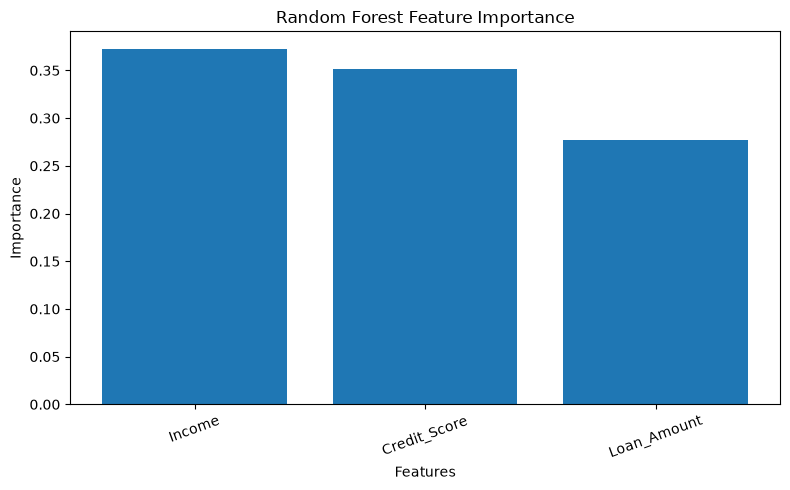

In [7]:
#Visualize feature importance
# Get feature importance
importance = model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

# Plot feature importance
plt.figure(figsize=(8, 5))

plt.bar(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
#Predict loan approval for a new applicant
# Take input from user

income = int(input("Enter annual income: "))
credit_score = int(input("Enter credit score: "))
loan_amount = int(input("Enter loan amount: "))

# Create new applicant data
new_applicant = pd.DataFrame({
    "Income": [income],
    "Credit_Score": [credit_score],
    "Loan_Amount": [loan_amount]
})

# Make prediction
prediction = model.predict(new_applicant)

# Display result
if prediction[0] == 1:
    print("Prediction: Loan Approved")
else:
    print("Prediction: Loan Rejected")